# 04 — EDA 정리 (모델 학습 없음)

노트북 03 에서 확인된 것: 이 RF 의 해상도 상한이

$$\text{BSS}_{\max} = \frac{\mathrm{Var}(p)}{r(1-r)} = 0.00421 \;\Rightarrow\; 421\text{점}$$

기울기 보정까지 넣어야 ~550점인데, 그게 이미 베이스라인 리더보드 점수다.
**캘리브레이션 계열의 상한은 이미 도달돼 있고, 그 위는 전부 해상도**에서 나와야 한다.

이 노트북은 모델을 하나도 학습하지 않는다. 다루는 것:

1. $r_{2025}$ 추정 — 점수 민감도와 성분별 외삽
2. 팀13 편향 재확인 (`n_R` 기준 필터로 수정)
3. 디코딩 신규 피처의 **해상도 기여를 점수로** 측정
4. 볼카운트 조건부 이력의 변별력
5. cold-start 실측 — 커스텀 이력 피처의 커버리지
6. (부록) isotonic 이득이 진짜인지 split-sample 검증

노트북 02 의 `artifacts/decoded_pitch_outcomes.parquet` 가 필요하다.

In [29]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [30]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 190)
pd.set_option("display.max_columns", 80)

DATA_DIR = "/content/drive/MyDrive/lgaimers_9/data"
ART_DIR = "/content/drive/MyDrive/lgaimers_9/artifacts"
TARGET = "control_success"

train = pd.read_csv(os.path.join(DATA_DIR, "train.csv"), encoding="utf-8-sig")
dec = pd.read_parquet(os.path.join(ART_DIR, "decoded_pitch_outcomes.parquet"))
print("train:", train.shape, "| decoded:", dec.shape)

# row_id 로 결합 (각 투수 마지막 1구는 디코딩 불가 -> NaN)
D = train.merge(dec[["row_id", "middle", "reverse", "far_off", "ball", "strike",
                     "fastball", "breaking", "offspeed"]], on="row_id", how="left")
D["overlap"] = ((D["middle"] == 1) & (D["reverse"] == 1)).astype(float)
D.loc[D["middle"].isna(), "overlap"] = np.nan
print("결합 후 결측(middle):", int(D["middle"].isna().sum()))

train: (1475092, 49) | decoded: (1474300, 15)
결합 후 결측(middle): 792


## 1. $r_{2025}$ 추정

### 1-1. 점수 민감도 — 분모가 얼마나 예민한가

$$\text{Score} = 10^5\left(1 - \frac{\mathrm{BS}}{r(1-r)}\right)$$

비율이 0.995 근처라 분모의 작은 변화가 40만 배로 증폭된다.
**BS 를 고정하고 $r$ 만 흔들어 본다.**

    r   r(1-r)  score
0.440 0.246400    0.0
0.445 0.246975    0.0
0.450 0.247500    0.0
0.455 0.247975    0.0
0.460 0.248400    0.0
0.465 0.248775    2.4
0.470 0.249100  132.9
0.475 0.249375  243.0
0.480 0.249600  332.9
0.485 0.249775  402.8
0.490 0.249900  452.6
0.495 0.249975  482.4
0.500 0.250000  492.4
0.505 0.249975  482.4
0.510 0.249900  452.6
0.515 0.249775  402.8
0.520 0.249600  332.9
0.525 0.249375  243.0
0.530 0.249100  132.9
0.535 0.248775    2.4
0.540 0.248400    0.0


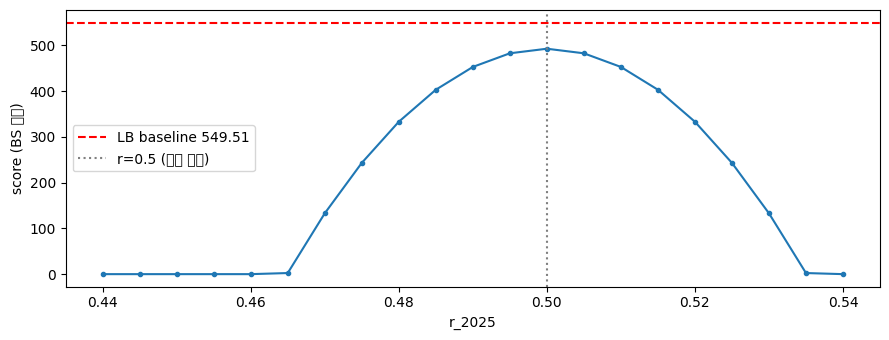


※ r=0.5 에서 점수가 최대. 이보다 멀어지면 분모가 작아져 점수가 내려간다.
※ 같은 BS 로 LB 549.51 에 도달 불가 -> 최종 모델의 BS 가 실제로 더 낮았다는 뜻


In [31]:
BS_FIXED = 0.248769          # 노트북 03 fold D 의 Brier
rows = []
for r in np.arange(0.440, 0.541, 0.005):
    den = r * (1 - r)
    rows.append({"r": round(r, 3), "r(1-r)": round(den, 6),
                 "score": round(max(0.0, 1e5 * (1 - BS_FIXED / den)), 1)})
sens = pd.DataFrame(rows)
print(sens.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(sens["r"], sens["score"], "-o", ms=3)
ax.axhline(549.51, color="r", ls="--", label="LB baseline 549.51")
ax.axvline(0.5, color="gray", ls=":", label="r=0.5 (분모 최대)")
ax.set_xlabel("r_2025"); ax.set_ylabel("score (BS 고정)"); ax.legend()
plt.tight_layout(); plt.show()

print("\n※ r=0.5 에서 점수가 최대. 이보다 멀어지면 분모가 작아져 점수가 내려간다.")
print("※ 같은 BS 로 LB 549.51 에 도달 불가 -> 최종 모델의 BS 가 실제로 더 낮았다는 뜻")

### 1-2. 성분별 추세

실패는 세 성분의 **합집합**이므로

$$\text{fail} = \text{middle} + \text{reverse} - \text{overlap} + \text{far\_off}$$

성분마다 추세가 다르다 (특히 `middle` 은 2024 ABS 도입에 급증).
총합을 한 번에 외삽하는 것보다 성분별 외삽이 나을 수 있다.
**R 전용**으로 본다 — 2022 이전 F 는 라벨 생성 과정이 다르다.

In [32]:
R = D[(D.game_type == "R") & D["middle"].notna()]
comp = R.groupby("season").agg(
    success=(TARGET, "mean"), middle=("middle", "mean"), reverse=("reverse", "mean"),
    far_off=("far_off", "mean"), overlap=("overlap", "mean"), n=(TARGET, "size"))
comp["fail_check"] = comp["middle"] + comp["reverse"] - comp["overlap"] + comp["far_off"]
comp["identity_err"] = (1 - comp["success"]) - comp["fail_check"]
print(comp.round(5).to_string())
print("\nidentity_err 이 0 이어야 분해가 정확 (부호 규약 확인용)")

        success   middle  reverse  far_off  overlap       n  fail_check  identity_err
season                                                                               
2019    0.54949  0.13010  0.18836  0.16275  0.03071  211608     0.45051           0.0
2020    0.52692  0.14433  0.21530  0.14730  0.03385  220857     0.47308           0.0
2021    0.51277  0.15007  0.26232  0.11949  0.04464  221199     0.48723           0.0
2022    0.50369  0.15240  0.25859  0.12689  0.04157  217000     0.49631           0.0
2023    0.50313  0.15769  0.25072  0.12285  0.03439  219776     0.49687           0.0
2024    0.48967  0.17848  0.24270  0.12139  0.03224  223264     0.51033           0.0

identity_err 이 0 이어야 분해가 정확 (부호 규약 확인용)


In [33]:
def extrapolate(s, target=2025, k=None, damp=1.0):
    # k: 최근 k 시즌만 사용. damp: 1이면 추세 완전 반영, 0이면 마지막 값 유지
    v = s.dropna()
    if k:
        v = v.iloc[-k:]
    x = v.index.values.astype(float)
    b, a = np.polyfit(x, v.values, 1)
    trend = a + b * target
    last = v.values[-1]
    return last + damp * (trend - last), b


print(f"{'성분':10s} {'2024':>9s} | {'전체추세':>9s} {'최근3':>9s} {'최근2':>9s} | {'기울기/시즌':>12s}")
est = {}
for c in ["success", "middle", "reverse", "far_off", "overlap"]:
    full, b_full = extrapolate(comp[c])
    k3, _ = extrapolate(comp[c], k=3)
    k2, _ = extrapolate(comp[c], k=2)
    est[c] = dict(last=comp[c].iloc[-1], full=full, k3=k3, k2=k2, slope=b_full)
    print(f"{c:10s} {comp[c].iloc[-1]:9.5f} | {full:9.5f} {k3:9.5f} {k2:9.5f} | {b_full:+12.5f}")

# 성분 합성 vs 직접 외삽
for key, lab in [("full", "전체추세"), ("k3", "최근3시즌"), ("k2", "최근2시즌")]:
    fail = est["middle"][key] + est["reverse"][key] - est["overlap"][key] + est["far_off"][key]
    print(f"\n[{lab}] 성분 합성 r = {1-fail:.5f}   |   success 직접 외삽 r = {est['success'][key]:.5f}")

성분              2024 |      전체추세       최근3       최근2 |       기울기/시즌
success      0.48967 |   0.47632   0.48480   0.47621 |     -0.01085
middle       0.17848 |   0.18061   0.18894   0.19928 |     +0.00812
reverse      0.24270 |   0.27376   0.23479   0.23468 |     +0.01069
far_off      0.12139 |   0.10617   0.11820   0.11992 |     -0.00779
overlap      0.03224 |   0.03685   0.02674   0.03009 |     +0.00018

[전체추세] 성분 합성 r = 0.47632   |   success 직접 외삽 r = 0.47632

[최근3시즌] 성분 합성 r = 0.48480   |   success 직접 외삽 r = 0.48480

[최근2시즌] 성분 합성 r = 0.47621   |   success 직접 외삽 r = 0.47621


In [34]:
# 감쇠 계수별 R 추정 + F 를 섞은 최종 합성
F = D[(D.game_type == "F") & D["middle"].notna() & (D.season >= 2023)]   # 2023+ 만 유효
f_by_season = F.groupby("season")[TARGET].mean()
f_share = (D.game_type == "F").mean()
print("F 시즌별 (2023+):", f_by_season.round(5).to_dict(), "| F 비중:", round(f_share, 4))

print(f"\n{'damp':>6} {'R_2025':>9} {'F_2025':>9} {'합성 r':>9} {'r(1-r)':>9} {'BS고정 점수':>12}")
for damp in [0.0, 0.25, 0.5, 0.75, 1.0]:
    r_R, _ = extrapolate(comp["success"], k=3, damp=damp)
    if len(f_by_season) >= 2:
        r_F, _ = extrapolate(f_by_season, damp=damp)
    else:
        r_F = f_by_season.iloc[-1]
    r_mix = (1 - f_share) * r_R + f_share * r_F
    den = r_mix * (1 - r_mix)
    print(f"{damp:>6.2f} {r_R:9.5f} {r_F:9.5f} {r_mix:9.5f} {den:9.6f} "
          f"{max(0.0, 1e5*(1-BS_FIXED/den)):12.1f}")

print("\n※ test 가 R 전용이면 '합성 r' 대신 R_2025 를 쓴다 (test 샘플 5건은 모두 R)")

F 시즌별 (2023+): {2023: 0.47284, 2024: 0.45896} | F 비중: 0.1091

  damp    R_2025    F_2025      합성 r    r(1-r)      BS고정 점수
  0.00   0.48967   0.45896   0.48632  0.249813        417.8
  0.25   0.48845   0.45549   0.48485  0.249771        401.0
  0.50   0.48724   0.45202   0.48339  0.249724        382.5
  0.75   0.48602   0.44855   0.48193  0.249673        362.3
  1.00   0.48480   0.44508   0.48047  0.249619        340.3

※ test 가 R 전용이면 '합성 r' 대신 R_2025 를 쓴다 (test 샘플 5건은 모두 R)


## 2. 팀13 편향 재확인

노트북 03 진단은 `n_total >= 500` 으로 걸렀는데, `n_total` 은 R+F 합계라
**2군에서만 500구를 채운 투수**가 팀13에 대거 포함됐다 (팀13 68명 vs 다른 팀 36~51명).
`n_R` 기준으로 다시 본다.

In [35]:
P = D.sort_values(["pitcher_id", "asof_pitcher_n"], kind="mergesort").reset_index(drop=True)
isR = (P.game_type == "R").to_numpy().astype(np.int64)
y = P[TARGET].to_numpy().astype(np.int64)
P["_isR"], P["_yR"] = isR, y * isR
cn = P.groupby("pitcher_id")["_isR"].cumsum() - P["_isR"]
cy = P.groupby("pitcher_id")["_yR"].cumsum() - P["_yR"]
P["asof_n_R"] = cn
P["asof_success_R"] = np.where(cn > 0, cy / cn, np.nan)

last = P.groupby("pitcher_id").tail(1).set_index("pitcher_id")
team = P.groupby("pitcher_id")["pitcher_team_id"].agg(lambda s: s.mode().iloc[0]).rename("team")
cmp2 = last[["asof_pitcher_success_rate", "asof_success_R", "asof_n_R", "asof_pitcher_n"]].join(team)

for label, sel in [("n_total>=500 (기존, 잘못된 필터)", cmp2["asof_pitcher_n"] >= 500),
                   ("n_R>=500 (수정)", cmp2["asof_n_R"] >= 500)]:
    c = cmp2[sel]
    t13m = c.loc[c.team == 13, "asof_pitcher_success_rate"].mean()
    othm = c.loc[c.team != 13, "asof_pitcher_success_rate"].mean()
    t13r = c.loc[c.team == 13, "asof_success_R"].mean()
    othr = c.loc[c.team != 13, "asof_success_R"].mean()
    print(f"--- {label} ---")
    print(f"   팀13 투수 수 {int((c.team==13).sum()):3d} / 전체 {len(c)}")
    print(f"   혼합(원본) 팀13-나머지 = {t13m-othm:+.4f}")
    print(f"   R전용(재구성) 팀13-나머지 = {t13r-othr:+.4f}\n")

print(cmp2[cmp2.asof_n_R >= 500].groupby("team")[
    ["asof_pitcher_success_rate", "asof_success_R"]].agg(["mean", "size"]).round(4).to_string())

--- n_total>=500 (기존, 잘못된 필터) ---
   팀13 투수 수  68 / 전체 465
   혼합(원본) 팀13-나머지 = +0.0349
   R전용(재구성) 팀13-나머지 = -0.0243

--- n_R>=500 (수정) ---
   팀13 투수 수  39 / 전체 409
   혼합(원본) 팀13-나머지 = +0.0201
   R전용(재구성) 팀13-나머지 = -0.0136

     asof_pitcher_success_rate      asof_success_R     
                          mean size           mean size
team                                                   
12                      0.5226   41         0.5153   41
13                      0.5347   39         0.4929   39
14                      0.5179   44         0.5018   44
15                      0.5170   38         0.5133   38
16                      0.5099   48         0.5043   48
17                      0.5156   46         0.5035   46
18                      0.5234   38         0.5187   38
19                      0.5029   43         0.4973   43
20                      0.5129   31         0.5063   31
21                      0.5103   41         0.5011   41


## 3. 피처의 해상도 기여를 점수로 측정 — 모델 없이

각 피처를 **학습 구간에서 분위 구간화 + 구간별 평균(EB 축소)** 하고
**다음 시즌에서 평가**한다. 사실상 1차원 lookup 모델이고,
out-of-time 이라 낙관 편향이 없다.

결과는 리더보드 점수 환산. 베이스라인 RF 가 415~550 이므로,
단일 피처가 100점을 넘으면 상당히 강한 신호다.

In [36]:
def _score_pair(p, yv):
    p = np.asarray(p, float); yv = np.asarray(yv, float)
    r = yv.mean(); den = r * (1 - r)
    bias = p.mean() - r
    pts_raw = 1e5 * (1 - np.mean((p - yv) ** 2) / den)   # 클리핑 없음
    pts_res = 1e5 * (1 - np.mean((p - bias - yv) ** 2) / den)   # 오라클 절편 = 해상도만
    return float(pts_res), float(pts_raw), float(bias)

In [37]:
def feature_resolution(tr, va, col, n_bins=20, k_shrink=200.0):
    xt = tr[col].to_numpy(float); xv = va[col].to_numpy(float)
    fin = np.isfinite(xt)
    if fin.sum() < 1000: return None
    edges = np.unique(np.nanquantile(xt[fin], np.linspace(0, 1, n_bins + 1)))
    if len(edges) < 3: return None
    def assign(v):
        b = np.digitize(v, edges[1:-1]).astype(float); b[~np.isfinite(v)] = -1.0; return b
    bt, bv = assign(xt), assign(xv)
    yt = tr[TARGET].to_numpy(float); yv = va[TARGET].to_numpy(float)
    prior = yt.mean()
    g = pd.DataFrame({"b": bt, "y": yt}).groupby("b")["y"].agg(["sum", "size"])
    lut = ((g["sum"] + prior * k_shrink) / (g["size"] + k_shrink)).to_dict()
    p = np.array([lut.get(b, prior) for b in bv])
    pts_res, pts_raw, bias = _score_pair(p, yv)
    return dict(col=col, pts_res=pts_res, pts_raw=pts_raw, bias=bias,
                n_bins=len(edges) - 1,
                nan_pct=round(float((~np.isfinite(xv)).mean() * 100), 2))


def group_resolution(tr, va, keys, label, k_shrink=200.0):
    yt = tr[TARGET].to_numpy(float); yv = va[TARGET].to_numpy(float)
    prior = yt.mean()
    g = tr.groupby(keys)[TARGET].agg(["sum", "size"])
    lut = ((g["sum"] + prior * k_shrink) / (g["size"] + k_shrink))
    p = va.set_index(keys).index.map(lut).to_numpy(dtype=float)
    miss = ~np.isfinite(p)
    p = np.where(miss, prior, p)
    pts_res, pts_raw, bias = _score_pair(p, yv)
    return dict(col=label, pts_res=pts_res, pts_raw=pts_raw, bias=bias,
                n_bins=len(g), miss_pct=round(float(miss.mean() * 100), 2))

In [38]:
# 신규 누적 피처 만들기 (strictly prior) — far_off / overlap / 성분 R전용
def add_prior_rate(df, src, name, mask=None):
    v = df[src].to_numpy(float)
    ok = np.isfinite(v)
    m = np.ones(len(df)) if mask is None else mask.astype(float)
    use = ok.astype(float) * m
    val = np.where(ok, v, 0.0) * m
    tmp = pd.DataFrame({"g": df["pitcher_id"].values, "u": use, "v": val})
    cu = tmp.groupby("g")["u"].cumsum() - tmp["u"]
    cv = tmp.groupby("g")["v"].cumsum() - tmp["v"]
    df[name] = np.where(cu > 0, cv / cu, np.nan)
    df[name + "_n"] = cu
    return df


maskR = (P.game_type == "R").to_numpy()
for src, nm in [("far_off", "asof_far_off"), ("overlap", "asof_overlap"),
                ("middle", "asof_middle_dec"), ("reverse", "asof_reverse_dec")]:
    P = add_prior_rate(P, src, nm)
    P = add_prior_rate(P, src, nm + "_R", mask=maskR)
P = add_prior_rate(P, TARGET, "asof_success_R2", mask=maskR)
print("신규 피처:", [c for c in P.columns if c.startswith("asof_") and c not in train.columns][:20])

신규 피처: ['asof_n_R', 'asof_success_R', 'asof_far_off', 'asof_far_off_n', 'asof_far_off_R', 'asof_far_off_R_n', 'asof_overlap', 'asof_overlap_n', 'asof_overlap_R', 'asof_overlap_R_n', 'asof_middle_dec', 'asof_middle_dec_n', 'asof_middle_dec_R', 'asof_middle_dec_R_n', 'asof_reverse_dec', 'asof_reverse_dec_n', 'asof_reverse_dec_R', 'asof_reverse_dec_R_n', 'asof_success_R2', 'asof_success_R2_n']


In [39]:
# 평가: 2021-2023 학습 -> 2024 평가, R 전용
# §3 평가 셀
tr = P[P.season.between(2021, 2023) & (P.game_type == "R")]   # ← R 전용 추가
va = P[(P.season == 2024) & (P.game_type == "R")]

print(f"tr={len(tr):,}  va={len(va):,}  (R 전용 평가)\n")

CANDIDATES = [
    # 주최 측 제공
    "asof_pitcher_success_rate", "asof_pitcher_middle_rate", "asof_pitcher_reverse_rate",
    "asof_pitcher_ball_rate", "asof_pitcher_strike_rate",
    "asof_pitcher_prev1_game_success_rate", "asof_pitcher_prev3_game_success_rate",
    "asof_pitcher_prev5_game_success_rate", "asof_batter_success_rate",
    "asof_pitcher_fastball_rate", "asof_pitcher_breaking_rate", "asof_pitcher_n",
    "li", "home_win_expectancy", "inning",
    # 디코딩 신규
    "asof_far_off", "asof_overlap", "asof_middle_dec", "asof_reverse_dec",
    # R 전용 재구성 (오염 제거)
    "asof_success_R2", "asof_far_off_R", "asof_overlap_R",
    "asof_middle_dec_R", "asof_reverse_dec_R",
]
res = [feature_resolution(tr, va, c) for c in CANDIDATES if c in P.columns]
res = pd.DataFrame([r for r in res if r]).sort_values("pts_res", ascending=False)
print(res.to_string(index=False))
print("\n※ 단일 피처 lookup 점수. 베이스라인 RF(47피처) 가 fold C 에서 420점")

tr=658,090  va=223,497  (R 전용 평가)

                                 col    pts_res     pts_raw     bias  n_bins  nan_pct
                     asof_success_R2 517.450355  505.610793 0.005439      20     0.03
           asof_pitcher_success_rate 434.571139  420.471188 0.005936      20     0.02
                  asof_reverse_dec_R 378.775450  315.991609 0.012526      20     0.03
asof_pitcher_prev5_game_success_rate 351.431488  321.358073 0.008669      20     1.00
                    asof_reverse_dec 342.503949  277.686279 0.012727      20     0.02
           asof_pitcher_reverse_rate 342.389506  277.579430 0.012726      20     0.02
asof_pitcher_prev3_game_success_rate 270.876709  225.435454 0.010656      20     1.00
              asof_pitcher_ball_rate 201.719405   86.528837 0.016966      20     0.02
asof_pitcher_prev1_game_success_rate 161.277528   85.520239 0.013759      20     1.00
            asof_pitcher_strike_rate 108.326524  -12.055246 0.017344      20     0.02
                   

## 4. 볼카운트 조건부 이력

제구 전략은 카운트에 따라 달라진다. 3-0 과 0-2 는 다른 게임이다.
투수 × 카운트 단위 이력이 전역 이력보다 변별력이 있는지 본다.

In [40]:
for df in (tr, va):
    df["cnt"] = df["balls_before"].astype(str) + "-" + df["strikes_before"].astype(str)

print("=== 카운트별 base rate / 성분 (R, 2024) ===")
t = va.groupby("cnt").agg(n=(TARGET, "size"), success=(TARGET, "mean"),
                          middle=("middle", "mean"), reverse=("reverse", "mean"),
                          far_off=("far_off", "mean"))
t["pct"] = (t["n"] / len(va) * 100).round(2)
print(t.round(4).sort_values("success").to_string())

print("\n=== 조합 lookup 의 해상도 (점수 환산) ===")
combos = [
    (["cnt"], "count only"),
    (["cnt", "pitcher_hand", "batter_hand"], "count x hands"),
    (["pitcher_id"], "pitcher only"),
    (["pitcher_id", "cnt"], "pitcher x count"),
    (["pitcher_id", "batter_hand"], "pitcher x batter_hand"),
    (["pitcher_id", "cnt", "batter_hand"], "pitcher x count x bhand"),
    (["batter_id"], "batter only"),
    (["pitcher_id", "batter_id"], "pitcher x batter"),
]
gr = pd.DataFrame([group_resolution(tr, va, k, lab) for k, lab in combos])
print(gr.sort_values("pts_res", ascending=False).to_string(index=False))
print("\n※ 조합이 세분화될수록 표본이 줄어 축소(k=200)에 눌린다.")
print("   pitcher x count 가 pitcher only 보다 높으면 조건부 이력이 실질 신호")


def hier_resolution(tr, va, keys, parent, label, k=50.0):
    # 전역 prior 가 아니라 상위 그룹(parent) 평균으로 축소 -> 세분화 조합에 공정
    yt = tr[TARGET].to_numpy(float); yv = va[TARGET].to_numpy(float)
    prior = yt.mean()
    pg = tr.groupby(parent)[TARGET].agg(["sum", "size"])
    plut = ((pg["sum"] + prior * 200.0) / (pg["size"] + 200.0))
    g = tr.groupby(keys)[TARGET].agg(["sum", "size"])
    par_of_cell = g.index.get_level_values(parent[0]) if len(parent) == 1 else None
    base = plut.reindex(par_of_cell).to_numpy() if par_of_cell is not None else prior
    base = np.where(np.isfinite(base), base, prior)
    lut = pd.Series((g["sum"].to_numpy() + base * k) / (g["size"].to_numpy() + k), index=g.index)
    p = va.set_index(keys).index.map(lut).to_numpy(dtype=float)
    fallback = va[parent[0]].map(plut).to_numpy(dtype=float)
    miss = ~np.isfinite(p)
    p = np.where(miss, np.where(np.isfinite(fallback), fallback, prior), p)
    pts_res, pts_raw, bias = _score_pair(p, yv)
    return dict(col=label, pts_res=pts_res, pts_raw=pts_raw, bias=bias,
                n_bins=len(g), miss_pct=round(float(miss.mean() * 100), 2))


print("\n=== 계층적 축소 (상위 그룹 = pitcher) ===")
hr = pd.DataFrame([
    hier_resolution(tr, va, ["pitcher_id", "cnt"], ["pitcher_id"], "pitcher x count (hier)"),
    hier_resolution(tr, va, ["pitcher_id", "batter_hand"], ["pitcher_id"], "pitcher x bhand (hier)"),
    hier_resolution(tr, va, ["pitcher_id", "cnt", "batter_hand"], ["pitcher_id"], "p x cnt x bhand (hier)"),
])
print(hr.sort_values("pts_res", ascending=False).to_string(index=False))
print("\n※ 계층 버전이 pitcher only 를 넘으면 조건부 신호가 실재")

=== 카운트별 base rate / 성분 (R, 2024) ===
         n  success  middle  reverse  far_off    pct
cnt                                                 
3-2  10403   0.4591  0.2036   0.2775   0.0940   4.65
3-1   5227   0.4637  0.2141   0.2822   0.0759   2.34
2-0   8177   0.4751  0.1938   0.2820   0.0823   3.66
2-1  11832   0.4778  0.1925   0.2742   0.0900   5.29
1-0  23181   0.4837  0.1922   0.2630   0.0957  10.37
3-0   2736   0.4876  0.2149   0.2434   0.0783   1.22
1-1  22332   0.4882  0.1818   0.2509   0.1127   9.99
0-0  57385   0.4902  0.1853   0.2528   0.1059  25.68
0-2  14321   0.4930  0.1419   0.1747   0.2148   6.41
2-2  18384   0.4940  0.1695   0.2429   0.1267   8.23
1-2  21751   0.4996  0.1508   0.2044   0.1729   9.73
0-1  27768   0.5088  0.1667   0.2178   0.1376  12.42

=== 조합 lookup 의 해상도 (점수 환산) ===
                    col    pts_res     pts_raw     bias  n_bins  miss_pct
  pitcher x batter_hand 370.718209  279.329609 0.015112     912     20.69
           pitcher only 291.334589  212

## 5. cold-start 실측

주최 측 `asof_*` 는 test 내부 2025 누적까지 반영돼 있지만,
**우리가 train 으로 만드는 커스텀 이력은 2025 신규 투수에게 전부 결측**이다.
그 비중이 커스텀 피처 전략의 실효 커버리지를 정한다.

In [41]:
seasons = sorted(train.season.unique())
rows = []
for i, s in enumerate(seasons):
    cur = train[train.season == s]
    if i == 0:
        continue
    prev_p = set(train.loc[train.season < s, "pitcher_id"])
    new_mask = ~cur["pitcher_id"].isin(prev_p)
    sub = cur[new_mask]
    rows.append({
        "season": s,
        "신규투수_행비중%": round(new_mask.mean() * 100, 2),
        "신규투수_수": int(sub["pitcher_id"].nunique()),
        "전체투수_수": int(cur["pitcher_id"].nunique()),
        "신규_평균투구수": round(sub.groupby("pitcher_id").size().mean(), 1) if len(sub) else 0,
        "신규_base_rate": round(sub[TARGET].mean(), 4) if len(sub) else np.nan,
        "기존_base_rate": round(cur[~new_mask][TARGET].mean(), 4),
    })
cs = pd.DataFrame(rows)
print(cs.to_string(index=False))
print(f"\n-> 2025 커스텀 이력 커버리지 추정: 약 {100-cs['신규투수_행비중%'].tail(3).mean():.1f}%")

# 신규 투수 구간에서 주최 측 asof 가 언제부터 쓸모 있는지
print("\n=== asof_pitcher_n 구간별 (R, 2024) ===")
va2 = va.copy()
va2["_nb"] = pd.cut(va2["asof_pitcher_n"], [-1, 0, 20, 100, 500, 2000, np.inf],
                    labels=["0", "1-20", "21-100", "101-500", "501-2k", "2k+"])
g = va2.groupby("_nb", observed=True).agg(n=(TARGET, "size"), base=(TARGET, "mean"))
g["pct"] = (g["n"] / len(va2) * 100).round(2)
# 구간 안에서 asof_success_rate 가 실제로 변별하는지
g["res_pts"] = [
    (feature_resolution(tr, va2[va2._nb == b], "asof_pitcher_success_rate") or {}).get("pts_res", np.nan)
    for b in g.index]   # ← "pts" → "pts_res"
print(g.round(4).to_string())

 season  신규투수_행비중%  신규투수_수  전체투수_수  신규_평균투구수  신규_base_rate  기존_base_rate
   2020      22.38     110     356     496.6        0.5422        0.5300
   2021      20.57      95     386     534.9        0.5288        0.5338
   2022      15.74      88     390     442.6        0.5439        0.5261
   2023      13.80      63     382     537.7        0.4986        0.5002
   2024      19.86      81     391     621.6        0.4899        0.4852

-> 2025 커스텀 이력 커버리지 추정: 약 83.5%

=== asof_pitcher_n 구간별 (R, 2024) ===
              n    base    pct    res_pts
_nb                                      
0            37  0.4595   0.02    -0.0000
1-20        742  0.4582   0.33  1640.5487
21-100     3224  0.4743   1.44   502.3412
101-500   17174  0.4762   7.68   289.0718
501-2k    53752  0.4778  24.05   504.5588
2k+      148568  0.4961  66.47   372.2382


## 6. (부록) isotonic 이득이 진짜인가

노트북 03 의 오라클 isotonic +41.8 점은 **같은 데이터에 적합하고 같은 데이터에서 평가**했다.
등방회귀의 in-sample optimism 은 대략 $2\sigma^2 k/n$ ($k$=블록 수) 이고,
$k \approx 53$ 만 넘어도 이득 전체가 과적합이다.

절반 적합 / 절반 평가로 정직한 값을 구한다. 모델 학습은 필요 없다
(노트북 03 이 저장한 `anchor_preds.npz` 사용).

In [42]:
from sklearn.isotonic import IsotonicRegression

try:
    ap = np.load(os.path.join(ART_DIR, "anchor_preds.npz"))
    pD = ap["D"]
    va_D = train[train.season == 2024]
    yD = va_D[TARGET].to_numpy(float)
    assert len(pD) == len(yD)

    r = yD.mean(); den = r * (1 - r)
    to_pts = lambda p, yy: max(0.0, 1e5 * (1 - np.mean((p - yy) ** 2) / den))

    rng = np.random.default_rng(0)
    h = rng.random(len(pD)) < 0.5

    iso_full = IsotonicRegression(out_of_bounds="clip").fit(pD, yD)
    print("isotonic 블록 수(전체 적합):", len(np.unique(iso_full.predict(pD))))
    print(f"optimism 임계 k = {1.045e-4 * len(pD) / (2*0.25):.0f} "
          f"(이보다 블록이 많으면 in-sample 이득은 대부분 과적합)\n")

    iso = IsotonicRegression(out_of_bounds="clip").fit(pD[h], yD[h])
    b_, a_ = np.polyfit(pD[h], yD[h], 1)
    bias_ = pD[h].mean() - yD[h].mean()

    print(f"{'':22s}{'in-sample':>12s}{'held-out':>12s}")
    print(f"{'raw':22s}{to_pts(pD, yD):12.2f}{to_pts(pD[~h], yD[~h]):12.2f}")
    print(f"{'절편만':22s}{'-':>12s}{to_pts(pD[~h]-bias_, yD[~h]):12.2f}")
    print(f"{'선형 OLS':22s}{'-':>12s}{to_pts(a_+b_*pD[~h], yD[~h]):12.2f}")
    print(f"{'isotonic':22s}{to_pts(iso_full.predict(pD), yD):12.2f}"
          f"{to_pts(iso.predict(pD[~h]), yD[~h]):12.2f}")
    print("\n※ held-out isotonic 이 선형을 못 넘으면 선형 재보정으로 충분")
except Exception as e:
    print("건너뜀:", e)

isotonic 블록 수(전체 적합): 43
optimism 임계 k = 53 (이보다 블록이 많으면 in-sample 이득은 대부분 과적합)

                         in-sample    held-out
raw                         415.57      376.77
절편만                              -      460.01
선형 OLS                           -      457.50
isotonic                    552.87      444.08

※ held-out isotonic 이 선형을 못 넘으면 선형 재보정으로 충분


## 7. 요약

In [43]:
print("=" * 78)
print("1) r_2025 — 점수는 분모에 매우 예민 (r 0.01 차이 = 100점대)")
print(f"   R 최근3시즌 외삽: {est['success']['k3']:.5f}  |  2024 실측: {comp['success'].iloc[-1]:.5f}")
print("\n2) 성분 추세 (R)")
for c in ["middle", "reverse", "far_off", "overlap"]:
    print(f"   {c:10s} 2024={comp[c].iloc[-1]:.5f}  기울기={est[c]['slope']:+.5f}/시즌")
print("\n3) 단일 피처 해상도 상위 5 (점수 환산)")
print(res.head(5)[["col", "pts_res", "pts_raw", "nan_pct"]].to_string(index=False))
print("\n4) 그룹 lookup 해상도 상위 5")
print(gr.sort_values("pts_res", ascending=False).head(5)[["col", "pts_res", "n_bins"]].to_string(index=False))
print(f"\n5) 2025 커스텀 이력 커버리지 추정: 약 {100-cs['신규투수_행비중%'].tail(3).mean():.1f}%")
print("=" * 78)

1) r_2025 — 점수는 분모에 매우 예민 (r 0.01 차이 = 100점대)
   R 최근3시즌 외삽: 0.48480  |  2024 실측: 0.48967

2) 성분 추세 (R)
   middle     2024=0.17848  기울기=+0.00812/시즌
   reverse    2024=0.24270  기울기=+0.01069/시즌
   far_off    2024=0.12139  기울기=-0.00779/시즌
   overlap    2024=0.03224  기울기=+0.00018/시즌

3) 단일 피처 해상도 상위 5 (점수 환산)
                                 col    pts_res    pts_raw  nan_pct
                     asof_success_R2 517.450355 505.610793     0.03
           asof_pitcher_success_rate 434.571139 420.471188     0.02
                  asof_reverse_dec_R 378.775450 315.991609     0.03
asof_pitcher_prev5_game_success_rate 351.431488 321.358073     1.00
                    asof_reverse_dec 342.503949 277.686279     0.02

4) 그룹 lookup 해상도 상위 5
                    col    pts_res  n_bins
  pitcher x batter_hand 370.718209     912
           pitcher only 291.334589     459
pitcher x count x bhand 273.029941   10372
        pitcher x count 260.414468    5380
          count x hands 124.070983      48

5) 